# 04 – Modèle FINAL, le plus robuste possible

Ce notebook produit **le modèle à déployer**. Il reprend les résultats du notebook 02 (variante M1, la meilleure) et corrige ses faiblesses mesurées :

| Faiblesse constatée (notebook 02) | Correction ici |
|---|---|
| 8 000 pas : la perte baissait encore | **16 000 pas** |
| Seulement 11 familles de falsifications | **Les 17 familles + 2 types composés** |
| Seuil SUSPICIOUS calibré sur la Tunisie : 11 % de fausses alarmes en Sicile (cible 5 %) | **Seuils calibrés sur le groupe géographique le plus exigeant** (Tunisie ET Sicile), choix du meilleur point d'entraînement sur ce même mélange |
| Fausses alarmes sur les vrais nuages (13 % à 26 %) | Vrais nuages **sur-échantillonnés à 20 %** et seuils tenant compte des nuages |
| Variations radiométriques légitimes limitées à ±3 % et 10 DN de bruit | **±8 % et jusqu'à 25 DN** appliqués aux deux classes : le modèle devient insensible aux traitements légitimes |
| Test de robustesse absent | **Test de stress** : gain ±10 %, bruit supplémentaire sur des scènes authentiques |
| Test petit (86 chips) : AUC sans incertitude | **Intervalles de confiance à 95 %** par famille (bootstrap par chip) |

**Important pour le rapport :** ce modèle a vu toutes les familles, et la Sicile a servi à choisir le point d'entraînement et les seuils. Il **n'a donc plus de jeu « inédit »** : les chiffres de généralisation du rapport viennent du notebook 02 (`MODE='research'`). Ici, on mesure la **robustesse** sur le jeu de test tunisien (jamais utilisé pour entraîner ni régler) et le stress test.

**Avant de lancer (Kaggle) :** *Add Input* → votre dataset de données (sortie du notebook 01) ; *Accelerator* = GPU T4 x2 ou P100 ; **Internet = On**. `QUICK = True` fait un essai de quelques minutes.

> Durée : 16 000 pas pour une seule variante, environ 1 h 05 sur T4 (extrapolé de 31 min pour 8 000 pas avec M1), plus 10 à 15 minutes d'évaluation. Utilisez *Save & Run All (Commit)*.

In [1]:
!pip -q install segmentation-models-pytorch cryptography onnx onnxruntime

In [2]:
%%writefile tp_lib.py
# tp_lib.py : bibliothèque commune du projet Trust the Pixel
# (falsifications, provenance/signature, modèle, entraînement, évaluation)
import os, json, time, uuid, hashlib, copy, math, warnings
import numpy as np
import cv2
cv2.setNumThreads(0)

BANDS = ['B02', 'B03', 'B04', 'B08']
CHIP = 256
DEFAULT_OFFSET = 1000
SEVERITY = {'subtle': (24, 40), 'medium': (40, 72), 'strong': (72, 128)}      # taille de la zone falsifiée (pixels)
SEV_ALL = ('subtle', 'medium', 'strong')

# ============================================================================
# 1. OUTILS DE FALSIFICATION (numpy / OpenCV)
#    Convention : x et donor sont des tableaux uint16 (C, H, W) avec le même décalage radiométrique `off`.
#    Chaque attaque renvoie (image uint16, masque uint8 (H, W), paramètres).
# ============================================================================
def feather(mask, sigma=2.0):
    return cv2.GaussianBlur(mask.astype(np.float32), (0, 0), float(sigma))

def to_u16(a):
    return np.clip(np.rint(a), 0, 65535).astype(np.uint16)

def shape_mask(size, rng):
    size = int(size)
    kind = str(rng.choice(['rect', 'ellipse', 'blob']))
    m = np.zeros((size, size), np.uint8)
    if kind == 'rect':
        m[:] = 1
    elif kind == 'ellipse':
        cv2.ellipse(m, (size // 2, size // 2), (max(size // 2 - 1, 2), max(size // 3, 2)),
                    float(rng.uniform(0, 180)), 0, 360, 1, -1)
    else:
        n = cv2.GaussianBlur(rng.normal(size=(size, size)).astype(np.float32), (0, 0), max(size / 6.0, 1.5))
        m = (n > np.quantile(n, 0.4)).astype(np.uint8)
        k, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        if k > 1:
            m = (lab == 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))).astype(np.uint8)
    if m.sum() == 0:
        m[:] = 1
    return m

def place(tpl, H, W, rng):
    h, w = tpl.shape
    y = int(rng.integers(0, H - h + 1)); x = int(rng.integers(0, W - w + 1))
    m = np.zeros((H, W), np.uint8)
    m[y:y + h, x:x + w] = tpl
    return m, y, x

def random_mask(H, W, size, rng):
    return place(shape_mask(size, rng), H, W, rng)[0]

_LAP = np.array([[-1, 2, -1], [2, -4, 2], [-1, 2, -1]], np.float32) / 4.0

def noise_sigma(x):
    # écart-type du bruit par bande (estimateur robuste MAD sur le résidu passe-haut)
    s = []
    for c in range(x.shape[0]):
        r = cv2.filter2D(x[c].astype(np.float32), -1, _LAP)
        s.append(1.4826 * np.median(np.abs(r - np.median(r))) / 1.5 + 1e-3)
    return np.asarray(s, np.float32)

def detectability(x, out, mask, sig=None):
    # score z du changement : (amplitude moyenne du changement / bruit du capteur) x racine(nombre de pixels modifiés).
    # Un score faible = changement noyé dans le bruit : l'attaque est statistiquement imperceptible.
    sel = mask > 0
    n = int(sel.sum())
    if n == 0:
        return 0.0
    d = np.abs(out.astype(np.float32) - x.astype(np.float32))[:, sel].mean(1)
    sig = noise_sigma(x) if sig is None else sig
    return float(np.mean(d / sig) * math.sqrt(n))

# ---- familles d'entraînement -------------------------------------------------
def copy_move(x, donor, size, rng, off):
    C, H, W = x.shape
    tpl = shape_mask(size, rng)
    _, sy, sx = place(tpl, H, W, rng)
    h, w = tpl.shape
    patch = x[:, sy:sy + h, sx:sx + w].astype(np.float32)
    pm = tpl.copy()
    k = int(rng.integers(0, 4))
    patch = np.rot90(patch, k, axes=(1, 2)); pm = np.rot90(pm, k)
    if rng.random() < 0.5:
        patch = patch[:, :, ::-1]; pm = pm[:, ::-1]
    patch = np.ascontiguousarray(patch); pm = np.ascontiguousarray(pm)
    ph, pw = pm.shape
    ty = tx = 0
    for _ in range(50):
        ty, tx = int(rng.integers(0, H - ph + 1)), int(rng.integers(0, W - pw + 1))
        if abs(ty - sy) > h or abs(tx - sx) > w:
            break
    a = feather(pm, 2.0)[None]
    out = x.astype(np.float32)
    out[:, ty:ty + ph, tx:tx + pw] = a * patch + (1 - a) * out[:, ty:ty + ph, tx:tx + pw]
    mask = np.zeros((H, W), np.uint8)
    mask[ty:ty + ph, tx:tx + pw] = pm
    return to_u16(out), mask, {'rot90': k}

def splice(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    d = donor.astype(np.float32).copy()
    match = bool(rng.random() < 0.7)
    if match:
        for c in range(C):
            xs = x[c][m > 0].astype(np.float32)
            d[c] = (d[c] - d[c].mean()) / (d[c].std() + 1e-6) * (xs.std() + 1e-6) + xs.mean()
    a = feather(m, float(rng.uniform(1.0, 3.0)))[None]
    return to_u16(a * d + (1 - a) * x.astype(np.float32)), m, {'stats_matched': match}

def class_swap(x, donor, size, rng, off):
    # colle une VRAIE zone d'eau ou de végétation prise ailleurs (fausse inondation, faux champ irrigué)
    C, H, W = x.shape
    size = int(size)
    d = (donor.astype(np.float32) - off) / 10000.0
    b, g, r, n = d
    eps = 1e-4
    kind = str(rng.choice(['water', 'vegetation']))
    score = (g - n) / (g + n + eps) if kind == 'water' else (n - r) / (n + r + eps)
    k = size // 2 * 2 + 1
    box = cv2.blur(score.astype(np.float32), (k, k))
    ys, xs = np.where(box >= np.quantile(box, 0.98))
    j = int(rng.integers(len(ys)))
    y0 = int(np.clip(ys[j] - size // 2, 0, H - size)); x0 = int(np.clip(xs[j] - size // 2, 0, W - size))
    tpl = shape_mask(size, rng)
    patch = donor[:, y0:y0 + size, x0:x0 + size].astype(np.float32)
    m, ty, tx = place(tpl, H, W, rng)
    a = feather(tpl, 2.0)[None]
    out = x.astype(np.float32)
    out[:, ty:ty + size, tx:tx + size] = a * patch + (1 - a) * out[:, ty:ty + size, tx:tx + size]
    return to_u16(out), m, {'classe': kind}

def _affine_region(x, size, rng, make_M):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    ys, xs = np.where(m)
    M = make_M((float(xs.mean()), float(ys.mean())))
    warped = np.stack([cv2.warpAffine(x[c].astype(np.float32), M, (W, H), flags=cv2.INTER_CUBIC,
                                      borderMode=cv2.BORDER_REFLECT) for c in range(C)])
    mm = np.maximum(m, cv2.warpAffine(m, M, (W, H), flags=cv2.INTER_NEAREST))
    a = feather(mm, 2.0)[None]
    return to_u16(a * warped + (1 - a) * x.astype(np.float32)), mm

def _rotate(x, size, rng, lo, hi):
    angle = float(rng.uniform(lo, hi)) * (1 if rng.random() < 0.5 else -1)
    out, mm = _affine_region(x, size, rng, lambda c: cv2.getRotationMatrix2D(c, angle, 1.0))
    return out, mm, {'angle': round(angle, 1)}

def rotate_region(x, donor, size, rng, off):
    return _rotate(x, size, rng, 5, 40)

def rotate_big(x, donor, size, rng, off):                  # paramètres inédits (test)
    return _rotate(x, size, rng, 45, 90)

def scale_region(x, donor, size, rng, off):
    f = float(rng.uniform(0.75, 1.3))
    if abs(f - 1) < 0.08:
        f = 1.15
    out, mm = _affine_region(x, size, rng, lambda c: cv2.getRotationMatrix2D(c, 0.0, f))
    return out, mm, {'facteur': round(f, 2)}

def spectral_edit(x, donor, size, rng, off):
    C, H, W = x.shape
    mode = str(rng.choice(['greenify', 'dry', 'flood']))
    if mode == 'greenify':
        g = [1, 1, rng.uniform(.7, .9), rng.uniform(1.2, 1.5)]
    elif mode == 'dry':
        g = [1, 1, rng.uniform(1.1, 1.3), rng.uniform(.6, .85)]
    else:
        g = [rng.uniform(.95, 1.2), rng.uniform(.95, 1.15), rng.uniform(.85, 1.0), rng.uniform(.3, .6)]
    m = random_mask(H, W, size, rng)
    a = feather(m, float(rng.uniform(2, 4)))[None]
    xf = x.astype(np.float32)
    edited = (xf - off) * np.asarray(g, np.float32)[:, None, None] + off
    return to_u16(a * edited + (1 - a) * xf), m, {'mode': mode}

def photometric_region(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    gain, gamma = float(rng.uniform(0.7, 1.3)), float(rng.uniform(0.7, 1.4))
    refl = np.clip(x.astype(np.float32) - off, 0, None)
    ref = max(float(np.percentile(refl, 99.5)), 1.0)
    y = ref * np.power(np.clip(refl * gain / ref, 0, None), gamma) + off
    a = feather(m, 3.0)[None]
    return to_u16(a * y + (1 - a) * x.astype(np.float32)), m, {'gain': round(gain, 2), 'gamma': round(gamma, 2)}

def noise_region(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    xf = x.astype(np.float32)
    if rng.random() < 0.5:
        y = xf + rng.normal(0, float(rng.uniform(20, 120)), xf.shape).astype(np.float32); mode = 'gauss'
    else:
        y = (xf - off) * (1 + rng.normal(0, float(rng.uniform(.03, .12)), xf.shape).astype(np.float32)) + off; mode = 'speckle'
    a = feather(m, 3.0)[None]
    return to_u16(a * y + (1 - a) * xf), m, {'mode': mode}

def blur_region(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    xf = x.astype(np.float32)
    if rng.random() < 0.6:
        k = int(rng.choice([3, 5, 7])); y = np.stack([cv2.GaussianBlur(c, (k, k), 0) for c in xf]); mode = 'flou'
    else:
        amt = float(rng.uniform(0.8, 2.0))
        y = xf + amt * (xf - np.stack([cv2.GaussianBlur(c, (0, 0), 1.5) for c in xf])); mode = 'nettete'
    a = feather(m, 2.0)[None]
    return to_u16(a * y + (1 - a) * xf), m, {'mode': mode}

def jpeg_region(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    q = int(rng.integers(30, 86))
    dec = np.empty(x.shape, np.float32)
    for c in range(C):
        lo, hi = np.percentile(x[c], [0.5, 99.5]); sc = float(hi - lo) + 1e-6
        u8 = np.clip((x[c].astype(np.float32) - lo) / sc * 255, 0, 255).astype(np.uint8)
        ok, buf = cv2.imencode('.jpg', u8, [int(cv2.IMWRITE_JPEG_QUALITY), q])
        dec[c] = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255 * sc + lo
    a = feather(m, 1.5)[None]
    return to_u16(a * dec + (1 - a) * x.astype(np.float32)), m, {'qualite': q}

def object_insert(x, donor, size, rng, off):
    # petits objets brillants ou sombres (toits, véhicules, bateaux) à l'échelle de quelques pixels
    C, H, W = x.shape
    size = int(size)
    wy, wx = int(rng.integers(0, H - size + 1)), int(rng.integers(0, W - size + 1))
    out = x.astype(np.float32)
    mask = np.zeros((H, W), np.uint8)
    sign = 1.0 if rng.random() < 0.6 else -1.0
    n = int(rng.integers(2, 6))
    for _ in range(n):
        r = int(rng.integers(2, 6))
        cy = wy + int(rng.integers(r, size - r)); cx = wx + int(rng.integers(r, size - r))
        disc = np.zeros((H, W), np.float32)
        cv2.circle(disc, (cx, cy), r, 1.0, -1)
        out += feather(disc, 1.0)[None] * sign * float(rng.uniform(0.10, 0.35)) * 10000.0
        mask |= (cv2.dilate(disc.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0).astype(np.uint8)
    return to_u16(out), mask, {'n_objets': n}

# ---- familles réservées au test (jamais vues à l'entraînement en mode « recherche ») ---------
def _inpaint(x, size, rng, flag):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    out = x.astype(np.float32).copy()
    radius = int(rng.integers(3, 8))
    for c in range(C):
        lo, hi = np.percentile(x[c], [0.5, 99.5]); sc = float(hi - lo) + 1e-6
        u8 = np.clip((x[c].astype(np.float32) - lo) / sc * 255, 0, 255).astype(np.uint8)
        r = cv2.inpaint(u8, m, radius, flag).astype(np.float32) / 255 * sc + lo
        out[c] = np.where(m > 0, r, out[c])
    return to_u16(out), m, {'rayon': radius}

def inpaint_telea(x, donor, size, rng, off):
    return _inpaint(x, size, rng, cv2.INPAINT_TELEA)

def inpaint_ns(x, donor, size, rng, off):
    return _inpaint(x, size, rng, cv2.INPAINT_NS)

def cloud_region(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    noise = cv2.GaussianBlur(rng.random((H, W)).astype(np.float32), (0, 0), 10)
    noise = (noise - noise.min()) / (noise.max() - noise.min() + 1e-6)
    a = (feather(m, 6.0) * (0.6 + 0.4 * noise))[None]
    white = off + float(rng.uniform(2500, 4500)) * (0.8 + 0.2 * noise)[None]
    return to_u16(a * white + (1 - a) * x.astype(np.float32)), m, {}

def resample_region(x, donor, size, rng, off):
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    f = float(rng.uniform(0.5, 0.9)) if rng.random() < 0.7 else float(rng.uniform(1.1, 1.6))
    xf = x.astype(np.float32).transpose(1, 2, 0)
    small = cv2.resize(xf, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    back = cv2.resize(small, (W, H), interpolation=cv2.INTER_CUBIC).transpose(2, 0, 1)
    a = feather(m, 2.0)[None]
    return to_u16(a * back + (1 - a) * x.astype(np.float32)), m, {'facteur': round(f, 2)}

def band_shift(x, donor, size, rng, off):
    # décalage d'une bande de 1 à 2 pixels (indice de parallaxe entre bandes)
    C, H, W = x.shape
    m = random_mask(H, W, size, rng)
    band = int(rng.integers(0, C))
    dy = dx = 0
    while dy == 0 and dx == 0:
        dy, dx = int(rng.integers(-2, 3)), int(rng.integers(-2, 3))
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    sh = cv2.warpAffine(x[band].astype(np.float32), M, (W, H), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
    a = feather(m, 2.0)
    out = x.astype(np.float32).copy()
    out[band] = a * sh + (1 - a) * out[band]
    return to_u16(out), m, {'bande': BANDS[band], 'dy': dy, 'dx': dx}

FAMILIES = {
    'copy_move': copy_move, 'splice': splice, 'class_swap': class_swap, 'rotate': rotate_region,
    'scale': scale_region, 'spectral': spectral_edit, 'photometric': photometric_region,
    'noise': noise_region, 'blur': blur_region, 'jpeg': jpeg_region, 'object_insert': object_insert,
    'inpaint': inpaint_telea, 'inpaint_ns': inpaint_ns, 'cloud': cloud_region,
    'resample': resample_region, 'band_shift': band_shift, 'rotate_big': rotate_big,
}
TRAIN_FAMILIES = ['copy_move', 'splice', 'class_swap', 'rotate', 'scale', 'spectral', 'photometric',
                  'noise', 'blur', 'jpeg', 'object_insert']
HELDOUT_FAMILIES = ['inpaint', 'inpaint_ns', 'cloud', 'resample', 'band_shift', 'rotate_big']
ALL_FAMILIES = TRAIN_FAMILIES + HELDOUT_FAMILIES
COMPOUND_POOL = ['copy_move', 'splice', 'class_swap', 'rotate', 'scale', 'spectral', 'photometric', 'noise', 'blur', 'jpeg']
COMPOUND_MIXED_POOL = COMPOUND_POOL + ['inpaint', 'resample', 'cloud']
EVAL_FAMILIES = ALL_FAMILIES + ['compound', 'compound_mixed']

def compound(x, donor, off, rng, severity, pool):
    k = int(rng.integers(2, 4))
    chain = [str(n) for n in rng.choice(pool, size=k, replace=False)]
    cur = x
    mask = np.zeros(x.shape[1:], np.uint8)
    recs = []
    for n in chain:
        cur, m, r = _single_attack(cur, donor, n, severity, rng, off)
        mask |= m
        recs.append({'attack_type': n, 'parameters': r['parameters']})
    return cur, mask, {'attack_type': 'compound', 'severity': severity, 'chain': recs}

def _single_attack(x, donor, name, severity, rng, off):
    lo, hi = SEVERITY[severity]
    size = int(rng.integers(lo, hi + 1))
    out, mask, params = FAMILIES[name](x, donor, size, rng, off)
    return out, mask, {'attack_type': name, 'severity': severity, 'size': size, 'parameters': params}

def make_attack(x, donor, name, severity, rng, off):
    if name in ('compound', 'compound_mixed'):
        pool = COMPOUND_POOL if name == 'compound' else COMPOUND_MIXED_POOL
        out, mask, rec = compound(x, donor, off, rng, severity, pool)
        rec['attack_type'] = name
    else:
        out, mask, rec = _single_attack(x, donor, name, severity, rng, off)
    rec['detectability'] = round(detectability(x, out, mask), 2)
    return out, mask, rec

def benign(x, rng, gain=0.03, noise=10.0, vary=False):
    # variation légitime (gain global + bruit de capteur) : appliquée aux DEUX classes
    g = rng.uniform(1.0 - gain, 1.0 + gain)
    s = noise * (rng.uniform(0.25, 1.0) if vary else 1.0)
    n = rng.normal(0, s, x.shape)
    return to_u16(x.astype(np.float32) * g + n)

def make_sample(chips, offsets, i, names, p_attack, rng, severities=SEV_ALL, benign_p=0.5,
                geo_aug=False, min_detect=8.0, max_tries=4, benign_gain=0.03, benign_noise=10.0, benign_vary=False):
    # renvoie : réflectance (C,H,W) float32, masque (H,W) float32, label 0/1, enregistrement
    x = np.asarray(chips[i])
    off = float(offsets[i])
    if rng.random() < benign_p:
        x = benign(x, rng, benign_gain, benign_noise, benign_vary)
    label, mask, rec = 0.0, np.zeros(x.shape[1:], np.uint8), {'attack_type': 'none'}
    if p_attack > 0 and len(names) > 0 and rng.random() < p_attack:
        rec = {'attack_type': 'none', 'note': 'attaque imperceptible rejetée'}
        for _ in range(max_tries):
            j = int(rng.integers(len(chips)))
            if j == i and len(chips) > 1:
                j = (j + 1) % len(chips)
            donor = to_u16(np.asarray(chips[j]).astype(np.float32) - float(offsets[j]) + off)
            name = str(names[int(rng.integers(len(names)))])
            sev = str(severities[int(rng.integers(len(severities)))])
            out, m, r = make_attack(x, donor, name, sev, rng, off)
            if m.sum() > 0 and r['detectability'] >= min_detect:
                x, mask, rec, label = out, m, r, 1.0
                break
    if geo_aug:
        k = int(rng.integers(0, 4))
        x = np.rot90(x, k, axes=(1, 2)); mask = np.rot90(mask, k)
        if rng.random() < 0.5:
            x = x[:, :, ::-1]; mask = mask[:, ::-1]
        x = np.ascontiguousarray(x); mask = np.ascontiguousarray(mask)
    xt = np.clip((x.astype(np.float32) - off) / 10000.0, 0.0, 1.5)
    return xt, mask.astype(np.float32), label, rec

# ============================================================================
# 2. PROVENANCE ET SIGNATURE NUMÉRIQUE (hash SHA-256, signature Ed25519, arbre de hachage par tuiles)
# ============================================================================
import datetime as _dt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.hazmat.primitives import serialization
from cryptography.exceptions import InvalidSignature

TILE = 32

def canonical(obj):
    return json.dumps(obj, sort_keys=True, separators=(',', ':'), ensure_ascii=True).encode('utf-8')

def pixel_bytes(arr):
    return np.ascontiguousarray(arr, dtype=np.uint16).tobytes()

def sha256_hex(b):
    return hashlib.sha256(b).hexdigest()

def tile_hashes(arr, tile=TILE):
    C, H, W = arr.shape
    a = np.ascontiguousarray(arr, dtype=np.uint16)
    return [sha256_hex(a[:, y:y + tile, x:x + tile].tobytes()) for y in range(0, H, tile) for x in range(0, W, tile)]

def merkle_root_hex(leaves):
    level = [bytes.fromhex(h) for h in leaves]
    if not level:
        return sha256_hex(b'')
    while len(level) > 1:
        if len(level) % 2:
            level.append(level[-1])
        level = [hashlib.sha256(level[i] + level[i + 1]).digest() for i in range(0, len(level), 2)]
    return level[0].hex()

def public_key_id(pub):
    raw = pub.public_bytes(serialization.Encoding.Raw, serialization.PublicFormat.Raw)
    return hashlib.sha256(raw).hexdigest()[:16]

def _now_iso():
    return _dt.datetime.now(_dt.timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')

class Source:
    # « satellite » : seul détenteur de la clé privée ; produit un paquet signé
    def __init__(self, sensor_id='SENTINEL-2-L2A', sk=None):
        self._sk = sk if sk is not None else Ed25519PrivateKey.generate()
        self.public_key = self._sk.public_key()
        self.key_id = public_key_id(self.public_key)
        self.sensor_id = sensor_id
        self.counter = 0

    def acquire(self, arr, meta):
        arr = np.ascontiguousarray(arr, dtype=np.uint16).copy()
        self.counter += 1
        leaves = tile_hashes(arr)
        manifest = {
            'obs_id': str(uuid.uuid4()), 'sensor': self.sensor_id, 'key_id': self.key_id,
            'time_utc': str(meta.get('date', '')), 'issued_utc': _now_iso(),
            'geo': [float(meta.get('lon', 0.0)), float(meta.get('lat', 0.0))],
            'scene': str(meta.get('scene', '')), 'tile': str(meta.get('tile', '')),
            'window': [int(meta.get('r0', 0)), int(meta.get('c0', 0))],
            'shape': list(arr.shape), 'dtype': 'uint16', 'offset': int(meta.get('offset', DEFAULT_OFFSET)),
            'counter': self.counter, 'nonce': uuid.uuid4().hex,
            'sha256': sha256_hex(pixel_bytes(arr)), 'merkle_root': merkle_root_hex(leaves), 'tile_hashes': leaves,
        }
        sig = self._sk.sign(canonical(manifest)).hex()
        return {'pixels': arr, 'manifest': manifest, 'signature': sig}

class Ground:
    # station sol : ne détient que des clés publiques épinglées ; garde la mémoire anti-rejeu
    def __init__(self, trusted_keys, allowed_sensors=('SENTINEL-2-L2A',), aoi_boxes=None, tolerance_days=1):
        self.trusted = dict(trusted_keys)                  # key_id -> clé publique
        self.allowed_sensors = set(allowed_sensors)
        self.aoi_boxes = aoi_boxes                          # liste de (lon_min, lat_min, lon_max, lat_max) ou None
        self.tolerance_days = tolerance_days
        self.seen_nonces, self.last_counter = set(), {}

    def verify(self, pkg):
        res = {'provenance': 'UNKNOWN', 'integrity': 'UNVERIFIED', 'replay': False, 'plausible': True,
               'changed_tiles': [], 'reasons': []}
        man, arr, sig = pkg.get('manifest'), pkg.get('pixels'), pkg.get('signature')
        if man is None or arr is None:
            res['reasons'].append('paquet incomplet (manifeste ou pixels absents)')
            return res
        # 1) signature
        kid = man.get('key_id')
        pub = self.trusted.get(kid)
        if not sig:
            res['reasons'].append('signature absente : origine non vérifiable')
        elif pub is None:
            res['provenance'] = 'INVALID'
            res['reasons'].append(f'clé inconnue ({kid}) : signataire non reconnu')
        else:
            try:
                pub.verify(bytes.fromhex(sig), canonical(man))
                res['provenance'] = 'VALID'
            except (InvalidSignature, ValueError):
                res['provenance'] = 'INVALID'
                res['reasons'].append('signature invalide : manifeste modifié ou signé par un tiers')
        # 2) intégrité des pixels (le manifeste n'est digne de confiance que si la signature est valide)
        if res['provenance'] == 'VALID':
            ok_shape = list(arr.shape) == list(man['shape']) and str(arr.dtype) == man['dtype']
            same = ok_shape and sha256_hex(pixel_bytes(arr)) == man['sha256']
            res['integrity'] = 'PASS' if same else 'FAIL'
            if not same:
                res['reasons'].append('empreinte SHA-256 différente : pixels modifiés après la signature')
                if ok_shape:
                    now = tile_hashes(arr)
                    res['changed_tiles'] = [i for i, (a, b) in enumerate(zip(now, man['tile_hashes'])) if a != b]
            # 3) rejeu
            if man['nonce'] in self.seen_nonces or man['counter'] <= self.last_counter.get(kid, 0):
                res['replay'] = True
                res['reasons'].append('rejeu : nonce déjà vu ou compteur non croissant')
            else:
                self.seen_nonces.add(man['nonce'])
                self.last_counter[kid] = man['counter']
            # 4) plausibilité des métadonnées
            if man.get('sensor') not in self.allowed_sensors:
                res['plausible'] = False; res['reasons'].append('capteur non autorisé')
            try:
                t = _dt.datetime.strptime(str(man['time_utc'])[:10], '%Y-%m-%d').replace(tzinfo=_dt.timezone.utc)
                if t > _dt.datetime.now(_dt.timezone.utc) + _dt.timedelta(days=self.tolerance_days):
                    res['plausible'] = False; res['reasons'].append('date d\'acquisition dans le futur')
            except ValueError:
                res['plausible'] = False; res['reasons'].append('date d\'acquisition illisible')
            if self.aoi_boxes:
                lon, lat = man['geo']
                if not any(b[0] <= lon <= b[2] and b[1] <= lat <= b[3] for b in self.aoi_boxes):
                    res['plausible'] = False; res['reasons'].append('position hors des zones attendues')
        return res

# ---- attaques sur le canal (après la signature) -------------------------------------------
CHANNEL_ATTACKS = ['pixels', 'manifest_meta', 'manifest_rehash', 'resign', 'replay', 'strip']

def channel_attack(pkg, kind, rng, donor=None, old_pkg=None):
    # renvoie (paquet attaqué, vérité terrain {'mask': ..., 'detail': ...}) ; la vérité n'est jamais transmise à la station sol
    pk = {'pixels': pkg['pixels'].copy(), 'manifest': copy.deepcopy(pkg['manifest']), 'signature': pkg['signature']}
    off = float(pk['manifest']['offset'])
    truth = {'mask': None, 'detail': kind}
    def tamper_pixels():
        name = str(rng.choice(ALL_FAMILIES))
        d = donor if donor is not None else np.roll(pk['pixels'], 37, axis=2)
        for _ in range(6):
            out, m, rec = make_attack(pk['pixels'], d, name, str(rng.choice(SEV_ALL)), rng, off)
            if m.sum() > 0:
                break
        truth['mask'] = m; truth['detail'] = f'{kind}:{name}'
        return out
    if kind == 'pixels':
        pk['pixels'] = tamper_pixels()
    elif kind == 'manifest_meta':
        field = str(rng.choice(['geo', 'time_utc', 'scene', 'sensor']))
        if field == 'geo': pk['manifest']['geo'] = [pk['manifest']['geo'][0] + 0.5, pk['manifest']['geo'][1] - 0.4]
        elif field == 'time_utc': pk['manifest']['time_utc'] = '2019-01-01'
        elif field == 'scene': pk['manifest']['scene'] = 'FAUX_' + pk['manifest']['scene']
        else: pk['manifest']['sensor'] = 'CAMERA-INCONNUE'
        truth['detail'] = f'{kind}:{field}'
    elif kind == 'manifest_rehash':        # l'attaquant recalcule tous les hash mais ne peut pas re-signer
        pk['pixels'] = tamper_pixels()
        leaves = tile_hashes(pk['pixels'])
        pk['manifest'].update({'sha256': sha256_hex(pixel_bytes(pk['pixels'])), 'tile_hashes': leaves,
                               'merkle_root': merkle_root_hex(leaves)})
    elif kind == 'resign':                 # l'attaquant signe avec sa propre clé
        pk['pixels'] = tamper_pixels()
        evil = Source(sensor_id=pk['manifest']['sensor'])
        evil.counter = int(pk['manifest']['counter'])
        fake = evil.acquire(pk['pixels'], {'date': pk['manifest']['time_utc'], 'lon': pk['manifest']['geo'][0],
                                           'lat': pk['manifest']['geo'][1], 'scene': pk['manifest']['scene'],
                                           'tile': pk['manifest']['tile'], 'offset': pk['manifest']['offset']})
        pk = fake
    elif kind == 'replay':
        pk = {'pixels': old_pkg['pixels'].copy(), 'manifest': copy.deepcopy(old_pkg['manifest']), 'signature': old_pkg['signature']}
    elif kind == 'strip':
        pk['pixels'] = tamper_pixels(); pk['signature'] = None
    else:
        raise ValueError(kind)
    return pk, truth

def decide(ver, score, t_low, t_high):
    # moteur de confiance : combine les preuves déterministes (signature) et la preuve statistique (IA)
    why = list(ver['reasons'])
    if ver['integrity'] == 'FAIL' or ver['provenance'] == 'INVALID' or ver['replay']:
        return 'COMPROMISED', why
    if score is not None and score >= t_high:
        return 'COMPROMISED', why + [f'anomalie de contenu forte (score {score:.2f} ≥ {t_high:.2f})']
    if not ver['plausible']:
        return 'SUSPICIOUS', why
    if ver['provenance'] == 'UNKNOWN':
        return 'SUSPICIOUS', why + ['origine non vérifiée']
    if score is not None and score >= t_low:
        return 'SUSPICIOUS', why + [f'anomalie de contenu (score {score:.2f} ≥ {t_low:.2f})']
    return 'TRUSTED', why

class AuditLog:
    # journal chaîné par hash : toute modification d'une ligne passée casse la chaîne
    def __init__(self):
        self.entries, self.prev = [], '0' * 64
    def add(self, record):
        body = {'t': _now_iso(), 'prev': self.prev, 'record': record}
        h = sha256_hex(canonical(body))
        self.entries.append({**body, 'hash': h}); self.prev = h
        return h
    def verify(self):
        prev = '0' * 64
        for e in self.entries:
            body = {'t': e['t'], 'prev': e['prev'], 'record': e['record']}
            if e['prev'] != prev or sha256_hex(canonical(body)) != e['hash']:
                return False
            prev = e['hash']
        return True

# ============================================================================
# 3. DONNÉES : empreintes de fichiers (intégrité du jeu de données) et chargement vérifié
# ============================================================================
import pandas as pd

def file_sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

def verify_manifest(folder):
    mf = os.path.join(folder, 'data_manifest.json')
    if not os.path.isfile(mf):
        raise FileNotFoundError('data_manifest.json absent : relancez le notebook 01 jusqu\'à la fin')
    man = json.load(open(mf))
    for name, h in man['files'].items():
        p = os.path.join(folder, name)
        if not os.path.isfile(p):
            raise FileNotFoundError(f'fichier du jeu de données manquant : {name}')
        if file_sha256(p) != h:
            raise ValueError(f'EMPREINTE DIFFÉRENTE pour {name} : fichier corrompu ou modifié depuis la création du jeu')
    return man

def load_split_data(folder, verify=True):
    man = verify_manifest(folder) if verify else json.load(open(os.path.join(folder, 'data_manifest.json')))
    data = {}
    for s in ['train', 'val', 'test', 'external']:
        px = os.path.join(folder, f'{s}_x.npy')
        if not os.path.isfile(px):
            continue
        x = np.load(px); off = np.load(os.path.join(folder, f'{s}_off.npy'))
        meta = pd.read_csv(os.path.join(folder, f'{s}_meta.csv'))
        assert x.ndim == 4 and x.shape[1] == len(BANDS) and x.dtype == np.uint16, f'{s} : forme/type inattendus {x.shape} {x.dtype}'
        assert x.shape[2] == CHIP and x.shape[3] == CHIP, f'{s} : taille de chip inattendue'
        assert len(x) == len(off) == len(meta), f'{s} : tailles incohérentes'
        assert set(np.unique(off)).issubset({0.0, 1000.0}), f'{s} : décalage radiométrique inattendu'
        assert not (x.reshape(len(x), -1).max(1) == 0).any(), f'{s} : chip entièrement vide'
        data[s] = {'x': x, 'off': off.astype(np.float32), 'hard': meta['hard'].values.astype(bool), 'meta': meta}
    for need in ['train', 'val', 'test']:
        assert need in data and len(data[need]['x']) > 0, f'jeu {need} absent ou vide'
    names = list(data)
    for a in names:
        for b in names:
            if a < b:
                assert not (set(data[a]['meta'].scene) & set(data[b]['meta'].scene)), f'FUITE : scène commune entre {a} et {b}'
                if man.get('split_group') == 'tile':
                    assert not (set(data[a]['meta'].tile) & set(data[b]['meta'].tile)), f'FUITE : tuile commune entre {a} et {b}'
    stats = json.load(open(os.path.join(folder, 'band_stats.json')))
    return data, stats, man

def export_geotiff(chip, row, path):
    # exporte une chip (4,H,W) en GeoTIFF géoréférencé, ouvrable dans QGIS
    import rasterio
    from rasterio.transform import Affine
    tr = Affine(10.0, 0.0, float(row['x0']), 0.0, -10.0, float(row['y0']))
    with rasterio.open(path, 'w', driver='GTiff', height=chip.shape[1], width=chip.shape[2], count=chip.shape[0],
                       dtype=str(chip.dtype), crs=f"EPSG:{int(row['epsg'])}", transform=tr, compress='deflate') as dst:
        dst.write(chip)
        if chip.shape[0] == len(BANDS):
            dst.descriptions = tuple(BANDS)

# ============================================================================
# 4. MODÈLE (PyTorch) : normalisation et caractéristiques DANS le modèle (même traitement à l'entraînement et en service)
# ============================================================================
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression

class HighPass(nn.Module):
    def __init__(self, c=4):
        super().__init__()
        k = torch.tensor([[-1, 2, -1], [2, -4, 2], [-1, 2, -1]], dtype=torch.float32) / 4.0
        self.register_buffer('k', k[None, None].repeat(c, 1, 1, 1))
        self.c = c
    def forward(self, x):
        return F.conv2d(x, self.k, padding=1, groups=self.c)

def spectral_feats(x):                 # x : réflectance (B,4,H,W) ordre B02, B03, B04, B08
    b, g, r, n = x[:, 0:1], x[:, 1:2], x[:, 2:3], x[:, 3:4]
    eps = 1e-4
    ndvi = (n - r) / (n + r + eps)
    ndwi = (g - n) / (g + n + eps)
    rb = (r / (b + eps)).clamp(0, 5) / 5
    return torch.cat([ndvi, ndwi, rb], 1)

VARIANT_CH = {'M0': 4, 'M1': 8, 'M2': 7, 'M3': 11}
VARIANT_DESC = {'M0': 'pixels', 'M1': 'pixels + résidu passe-haut', 'M2': 'pixels + indices spectraux', 'M3': 'pixels + résidu + indices'}

def make_unet(in_ch, encoder='resnet18', weights='imagenet'):
    try:
        return smp.Unet(encoder, encoder_weights=weights, in_channels=in_ch, classes=1)
    except Exception as e:
        print(f'[avertissement] poids {weights} indisponibles ({type(e).__name__}) : initialisation aléatoire')
        return smp.Unet(encoder, encoder_weights=None, in_channels=in_ch, classes=1)

class Detector(nn.Module):
    # entrée : réflectance (B,4,H,W) = (DN - décalage) / 10000 ; sortie : logits du masque de falsification (B,1,H,W)
    def __init__(self, variant, mean, std, hp_std, encoder='resnet18', weights='imagenet'):
        super().__init__()
        assert variant in VARIANT_CH
        self.variant = variant
        self.register_buffer('mean', torch.tensor(mean, dtype=torch.float32).view(1, -1, 1, 1))
        self.register_buffer('std', torch.tensor(std, dtype=torch.float32).view(1, -1, 1, 1))
        self.hp_std = float(hp_std)
        self.hp = HighPass(len(BANDS))
        self.unet = make_unet(VARIANT_CH[variant], encoder, weights)
    def features(self, x):
        parts = [(x - self.mean) / self.std]
        if self.variant in ('M1', 'M3'):
            parts.append(self.hp(x).float() / self.hp_std)
        if self.variant in ('M2', 'M3'):
            parts.append(spectral_feats(x))
        return torch.cat(parts, 1)
    def forward(self, x):
        return self.unet(self.features(x))

def image_score(logits, k=200):
    return logits.flatten(1).topk(min(k, logits[0].numel()), dim=1).values.mean(1)

def compute_hp_std(chips, offs, n=64, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(chips), size=min(n, len(chips)), replace=False)
    x = np.stack([np.clip((chips[i].astype(np.float32) - offs[i]) / 10000.0, 0, 1.5) for i in idx])
    with torch.no_grad():
        return float(HighPass(len(BANDS))(torch.from_numpy(x)).std())

class ChipDS(Dataset):
    def __init__(self, chips, offs, names, p_attack=0.5, train=True, seed=0, repeat=1, severities=SEV_ALL,
                 geo_aug=None, min_detect=8.0, hard_idx=None, p_hard=0.0, benign_gain=0.03, benign_noise=10.0, benign_vary=False):
        self.benign = (benign_gain, benign_noise, benign_vary)
        self.chips, self.offs, self.names = chips, offs, list(names)
        self.p, self.train, self.seed, self.repeat = p_attack, train, seed, repeat
        self.sev, self.min_detect = tuple(severities), min_detect
        self.geo_aug = train if geo_aug is None else geo_aug
        self.hard_idx, self.p_hard = hard_idx, p_hard
    def __len__(self):
        return len(self.chips) * self.repeat
    def __getitem__(self, k):
        i = k % len(self.chips)
        rng = np.random.default_rng(None if self.train else self.seed * 1_000_003 + k)
        if self.train and self.hard_idx is not None and len(self.hard_idx) and rng.random() < self.p_hard:
            i = int(self.hard_idx[int(rng.integers(len(self.hard_idx)))])      # sur-échantillonne les VRAIS nuages
        xt, m, y, _ = make_sample(self.chips, self.offs, i, self.names, self.p, rng, severities=self.sev,
                                  geo_aug=self.geo_aug, min_detect=self.min_detect,
                                  benign_gain=self.benign[0], benign_noise=self.benign[1], benign_vary=self.benign[2])
        return torch.from_numpy(xt), torch.from_numpy(m[None]), torch.tensor(y, dtype=torch.float32)

class ModelEMA:
    def __init__(self, model, decay=0.998):
        self.module = copy.deepcopy(model).eval()
        self.decay = decay
        for p in self.module.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])

def auc_ap(y, s):
    y = np.asarray(y); s = np.asarray(s)
    if len(np.unique(y)) < 2:
        return float('nan'), float('nan')
    return float(roc_auc_score(y, s)), float(average_precision_score(y, s))

@torch.no_grad()
def run_scores(model, ds, device, bs=32, nw=0):
    model.eval()
    dl = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=nw)
    use_cuda = device.type == 'cuda'
    S, Y, IOU, DICE = [], [], [], []
    for x, m, y in dl:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_cuda):
            lg = model(x.to(device))
        lg = lg.float().cpu()
        S.append(image_score(lg)); Y.append(y)
        pred = (lg > 0).flatten(1); gt = (m > 0.5).flatten(1)
        inter = (pred & gt).sum(1).float(); union = (pred | gt).sum(1).float()
        pos = y > 0.5
        IOU.append((inter / (union + 1e-6))[pos]); DICE.append((2 * inter / (pred.sum(1) + gt.sum(1) + 1e-6))[pos])
    return {'scores': torch.cat(S).numpy(), 'labels': torch.cat(Y).numpy(),
            'iou': torch.cat(IOU).numpy(), 'dice': torch.cat(DICE).numpy()}

def default_cfg(**kw):
    cfg = dict(steps=8000, bs=32, lr=5e-4, ema=0.998, eval_every=500, val_rep=2, num_workers=2, seed=42,
               encoder='resnet18', weights='imagenet', names=list(TRAIN_FAMILIES), min_detect=8.0, p_hard=0.15,
               benign_gain=0.03, benign_noise=10.0, benign_vary=False)
    cfg.update(kw)
    return cfg

def train_variant(variant, stats, data, cfg, device, log=print):
    torch.manual_seed(cfg['seed']); np.random.seed(cfg['seed'])
    model = Detector(variant, stats['mean'], stats['std'], stats['hp_std'], cfg['encoder'], cfg['weights']).to(device)
    ema = ModelEMA(model, cfg['ema'])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=cfg['steps'], pct_start=0.1)
    use_cuda = device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_cuda)
    tr, va, nw = data['train'], data['val'], cfg['num_workers']
    ds = ChipDS(tr['x'], tr['off'], cfg['names'], 0.5, train=True, geo_aug=True, min_detect=cfg['min_detect'],
                hard_idx=np.where(tr['hard'])[0], p_hard=cfg['p_hard'],
                benign_gain=cfg['benign_gain'], benign_noise=cfg['benign_noise'], benign_vary=cfg['benign_vary'])
    dl = DataLoader(ds, batch_size=cfg['bs'], shuffle=True, num_workers=nw, drop_last=True,
                    persistent_workers=nw > 0, pin_memory=use_cuda)
    val_ds = ChipDS(va['x'], va['off'], cfg['names'], 0.5, train=False, seed=cfg['seed'] + 11,
                    repeat=cfg['val_rep'], min_detect=cfg['min_detect'],
                    benign_gain=cfg['benign_gain'], benign_noise=cfg['benign_noise'], benign_vary=cfg['benign_vary'])
    dice = smp.losses.DiceLoss('binary')
    step, hist, best, best_state, run_loss, n_run, t0 = 0, [], -1.0, None, 0.0, 0, time.time()
    while step < cfg['steps']:
        for x, m, y in dl:
            model.train()
            x, m, y = x.to(device, non_blocking=True), m.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_cuda):
                lg = model(x)
            lg = lg.float()
            sc = image_score(lg)
            loss = F.binary_cross_entropy_with_logits(lg, m) + dice(lg, m) + F.binary_cross_entropy_with_logits(sc, y)
            if not torch.isfinite(loss):
                opt.zero_grad(set_to_none=True); continue
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            ema.update(model, step)
            step += 1; run_loss += float(loss.item()); n_run += 1
            if step % cfg['eval_every'] == 0 or step == cfg['steps']:
                r = run_scores(ema.module, val_ds, device, bs=cfg['bs'], nw=nw)
                auc, ap = auc_ap(r['labels'], r['scores'])
                hist.append(dict(step=step, loss=run_loss / max(n_run, 1), val_auc=auc, val_ap=ap,
                                 lr=sched.get_last_lr()[0], minutes=(time.time() - t0) / 60))
                run_loss, n_run = 0.0, 0
                if np.isfinite(auc) and auc > best:
                    best, best_state = auc, copy.deepcopy(ema.module.state_dict())
                log(f'  {variant} pas {step}/{cfg["steps"]}  perte {hist[-1]["loss"]:.3f}  val AUC {auc:.3f}  AP {ap:.3f}  ({hist[-1]["minutes"]:.1f} min)')
            if step >= cfg['steps']:
                break
    if best_state is not None:
        ema.module.load_state_dict(best_state)
    return ema.module.eval(), pd.DataFrame(hist)

# ============================================================================
# 5. ÉVALUATION PAR FAMILLE, CALIBRATION, EXPORT
# ============================================================================
def score_negatives(model, split, device, n_rep=2, seed=1000, bs=32, nw=0):
    ds = ChipDS(split['x'], split['off'], [], 0.0, train=False, seed=seed, repeat=n_rep)
    r = run_scores(model, ds, device, bs, nw)
    idx = np.arange(len(ds)) % len(split['x'])
    return r['scores'], split['hard'][idx]

def score_family(model, split, family, device, n_rep=2, seed=2000, severities=SEV_ALL, min_detect=8.0, bs=32, nw=0):
    ds = ChipDS(split['x'], split['off'], [family], 1.0, train=False, seed=seed, repeat=n_rep,
                severities=severities, min_detect=min_detect)
    r = run_scores(model, ds, device, bs, nw)
    keep = r['labels'] > 0.5
    return {'scores': r['scores'][keep], 'n_req': len(ds), 'n_pos': int(keep.sum()),
            'iou': float(np.mean(r['iou'])) if len(r['iou']) else float('nan'),
            'dice': float(np.mean(r['dice'])) if len(r['dice']) else float('nan')}

def calibrate(model, val_split, names, device, n_rep=4, min_detect=8.0, bs=32, nw=0):
    neg, hard = score_negatives(model, val_split, device, n_rep, seed=3000, bs=bs, nw=nw)
    ds = ChipDS(val_split['x'], val_split['off'], names, 1.0, train=False, seed=3500, repeat=n_rep, min_detect=min_detect)
    r = run_scores(model, ds, device, bs, nw)
    pos = r['scores'][r['labels'] > 0.5]
    t_low, t_high = float(np.quantile(neg, 0.95)), float(np.quantile(neg, 0.995))
    s = np.r_[neg, pos].reshape(-1, 1); y = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
    lr = LogisticRegression(C=1e4, class_weight='balanced', max_iter=1000).fit(s, y)
    return {'t_low': t_low, 't_high': t_high, 'platt_a': float(lr.coef_[0, 0]), 'platt_b': float(lr.intercept_[0]),
            'n_neg': int(len(neg)), 'n_pos': int(len(pos))}

def trust_index(score, cal):
    p = 1.0 / (1.0 + math.exp(-(cal['platt_a'] * score + cal['platt_b'])))
    return float(100.0 * (1.0 - p))

def family_table(model, split, families, roles, cal, device, n_rep=2, min_detect=8.0, severities=SEV_ALL, bs=32, nw=0, seed=2000):
    neg, hard = score_negatives(model, split, device, n_rep, seed=seed - 1000, bs=bs, nw=nw)
    rows = [dict(famille='(authentiques)', role='négatifs', n_req=len(neg), n_pos=0,
                 fp_low=float((neg >= cal['t_low']).mean()), fp_high=float((neg >= cal['t_high']).mean()))]
    if hard.any():
        rows.append(dict(famille='(authentiques nuageux)', role='négatifs réels', n_req=int(hard.sum()), n_pos=0,
                         fp_low=float((neg[hard] >= cal['t_low']).mean()), fp_high=float((neg[hard] >= cal['t_high']).mean())))
    for fam in families:
        r = score_family(model, split, fam, device, n_rep, seed, severities, min_detect, bs, nw)
        pos = r['scores']
        auc, ap = (auc_ap(np.r_[np.zeros(len(neg)), np.ones(len(pos))], np.r_[neg, pos]) if len(pos) >= 5 else (float('nan'),) * 2)
        rows.append(dict(famille=fam, role=roles.get(fam, ''), n_req=r['n_req'], n_pos=r['n_pos'],
                         rejet=1 - r['n_pos'] / max(r['n_req'], 1), auc=auc, ap=ap,
                         tpr_low=float((pos >= cal['t_low']).mean()) if len(pos) else float('nan'),
                         tpr_high=float((pos >= cal['t_high']).mean()) if len(pos) else float('nan'),
                         iou=r['iou'], dice=r['dice']))
    return pd.DataFrame(rows)

def export_onnx(model, path, h=CHIP, w=CHIP):
    m = copy.deepcopy(model).cpu().eval()
    dummy = torch.rand(1, len(BANDS), h, w) * 0.3
    kw = dict(opset_version=17, input_names=['x'], output_names=['logits'],
              dynamic_axes={'x': {0: 'batch'}, 'logits': {0: 'batch'}})
    try:
        torch.onnx.export(m, dummy, path, dynamo=False, **kw)
    except TypeError:
        torch.onnx.export(m, dummy, path, **kw)
    return path

def onnx_check(model, path, n=3, runs=30):
    import onnxruntime as ort
    m = copy.deepcopy(model).cpu().eval()
    sess = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    x = torch.rand(n, len(BANDS), CHIP, CHIP) * 0.3
    with torch.no_grad():
        ref = m(x).numpy()
    out = sess.run(None, {'x': x.numpy()})[0]
    x1 = {'x': x[:1].numpy()}
    sess.run(None, x1)
    t = time.perf_counter()
    for _ in range(runs):
        sess.run(None, x1)
    return {'ecart_max': float(np.abs(ref - out).max()), 'ecart_rel': float(np.abs(ref - out).max() / (np.abs(ref).max() + 1e-9)), 'ms_par_chip': (time.perf_counter() - t) / runs * 1000,
            'taille_mo': os.path.getsize(path) / 1e6}

class Analyzer:
    # analyse un paquet reçu : ne reçoit QUE les pixels et le décalage radiométrique, jamais la vérité terrain
    def __init__(self, model, device, cal):
        self.model, self.device, self.cal = model.eval(), device, cal
    @torch.no_grad()
    def analyze(self, pixels, offset):
        x = np.clip((np.asarray(pixels).astype(np.float32) - float(offset)) / 10000.0, 0, 1.5)
        lg = self.model(torch.from_numpy(x)[None].to(self.device)).float().cpu()
        return {'score': float(image_score(lg)[0]), 'prob': torch.sigmoid(lg)[0, 0].numpy()}

def ground_station(pkg, ground, analyzer, cal):
    # chaîne complète côté station sol : vérification cryptographique, analyse IA, décision
    ver = ground.verify(pkg)
    off = pkg['manifest']['offset'] if ver['provenance'] == 'VALID' else DEFAULT_OFFSET
    ana = analyzer.analyze(pkg['pixels'], off)
    status, why = decide(ver, ana['score'], cal['t_low'], cal['t_high'])
    return {'status': status, 'reasons': why, 'verification': ver, 'score': ana['score'], 'prob': ana['prob'],
            'trust': trust_index(ana['score'], cal)}


Writing tp_lib.py


In [3]:
import os, sys, json, time, copy, math, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
import importlib, tp_lib
importlib.reload(tp_lib)
from tp_lib import *
warnings.filterwarnings('ignore', category=UserWarning)

QUICK = False
SEED = 42
VARIANT = 'M1'                         # meilleure variante du notebook 02 (pixels + résidu passe-haut)
STEPS, BS, EVAL_EVERY, VAL_REP = 16000, 32, 1000, 2
P_HARD = 0.20                          # part des tirages sur de vrais nuages
BENIGN = dict(benign_gain=0.08, benign_noise=25.0, benign_vary=True)    # variations légitimes plus larges
MIN_DETECT = 8.0
WEIGHTS = 'imagenet'
N_REP, N_BOOT = 2, 300
if QUICK:
    STEPS, BS, EVAL_EVERY, VAL_REP, N_REP, N_BOOT = 8, 4, 4, 1, 1, 30

IN_KAGGLE = Path('/kaggle').exists()
ROOT = Path('/kaggle/working') if IN_KAGGLE else Path('/content')
OUTM = ROOT / ('model_final_quick' if QUICK else 'model_final'); OUTM.mkdir(parents=True, exist_ok=True)
NUM_WORKERS = min(4, max(2, (os.cpu_count() or 2) - 1)) if torch.cuda.is_available() else 0
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('appareil :', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'ATTENTION : pas de GPU')
np.random.seed(SEED); torch.manual_seed(SEED)

TRAIN_NAMES = list(ALL_FAMILIES) + ['compound', 'compound_mixed']      # toutes les familles et les chaînes
ROLES = {f: 'entraînement' for f in EVAL_FAMILIES}
print(len(TRAIN_NAMES), 'familles d\'entraînement :', TRAIN_NAMES)

appareil : cuda | Tesla T4
19 familles d'entraînement : ['copy_move', 'splice', 'class_swap', 'rotate', 'scale', 'spectral', 'photometric', 'noise', 'blur', 'jpeg', 'object_insert', 'inpaint', 'inpaint_ns', 'cloud', 'resample', 'band_shift', 'rotate_big', 'compound', 'compound_mixed']


## 1. Données : entraînement tunisien, validation = Tunisie + Sicile

Le jeu `val` (Tunisie) et le jeu `external` (Sicile) sont **réunis** pour choisir le meilleur point d'entraînement. Le jeu `test` (Tunisie) reste **totalement à part** : il ne sert ni à entraîner, ni à régler.

In [4]:
def find_dir(marker):
    for base in [ROOT / 'data_split', Path('/kaggle/input'), Path('/content/drive/MyDrive/trust_the_pixel')]:
        if base.exists():
            if (base / marker).exists():
                return base
            for dp, dn, fn in os.walk(base):
                if marker in fn:
                    return Path(dp)
    raise FileNotFoundError(marker + ' introuvable : ajoutez le dataset de données (Add Input)')

DATA_DIR = find_dir('data_manifest.json')
data, stats, man = load_split_data(DATA_DIR, verify=True)
stats['hp_std'] = compute_hp_std(data['train']['x'], data['train']['off'], seed=SEED)

def concat_splits(a, b):
    return {'x': np.concatenate([a['x'], b['x']]), 'off': np.concatenate([a['off'], b['off']]),
            'hard': np.concatenate([a['hard'], b['hard']]), 'meta': pd.concat([a['meta'], b['meta']], ignore_index=True)}

val_mix = concat_splits(data['val'], data['external']) if 'external' in data else data['val']
groups = {'tunisie_val': data['val']}
if 'external' in data:
    groups['sicile_externe'] = data['external']
print('dossier :', DATA_DIR, '| empreintes vérifiées')
display(pd.DataFrame([dict(jeu=s, chips=len(d['x']), nuageuses=int(d['hard'].sum()), tuiles=d['meta'].tile.nunique()) for s, d in
                      {'train': data['train'], 'validation (Tunisie + Sicile)': val_mix, 'test (à part)': data['test']}.items()]))

dossier : path cant be shown becuase of anonymity | empreintes vérifiées


,jeu,chips,nuageuses,tuiles
0,train,1013,85,6
1,validation (Tunisie + Sicile),761,63,4
2,test (à part),86,15,2


## 2. Entraînement du modèle final (M1, 17 familles + chaînes, 16 000 pas)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

  M1 pas 1000/16000  perte 1.969  val AUC 0.662  AP 0.738  (4.2 min)
  M1 pas 2000/16000  perte 1.177  val AUC 0.769  AP 0.834  (8.5 min)
  M1 pas 3000/16000  perte 0.990  val AUC 0.817  AP 0.871  (12.7 min)
  M1 pas 4000/16000  perte 0.871  val AUC 0.832  AP 0.884  (16.8 min)
  M1 pas 5000/16000  perte 0.808  val AUC 0.848  AP 0.895  (21.1 min)
  M1 pas 6000/16000  perte 0.742  val AUC 0.855  AP 0.901  (25.3 min)
  M1 pas 7000/16000  perte 0.707  val AUC 0.861  AP 0.905  (29.6 min)
  M1 pas 8000/16000  perte 0.662  val AUC 0.865  AP 0.908  (33.8 min)
  M1 pas 9000/16000  perte 0.616  val AUC 0.882  AP 0.918  (38.1 min)
  M1 pas 10000/16000  perte 0.586  val AUC 0.889  AP 0.923  (42.3 min)
  M1 pas 11000/16000  perte 0.554  val AUC 0.887  AP 0.923  (46.6 min)
  M1 pas 12000/16000  perte 0.519  val AUC 0.891  AP 0.925  (50.8 min)
  M1 pas 13000/16000  perte 0.506  val AUC 0.891  AP 0.926  (55.0 min)
  M1 pas 14000/16000  perte 0.493  val AUC 0.895  AP 0.928  (59.3 min)
  M1 pas 15000/16

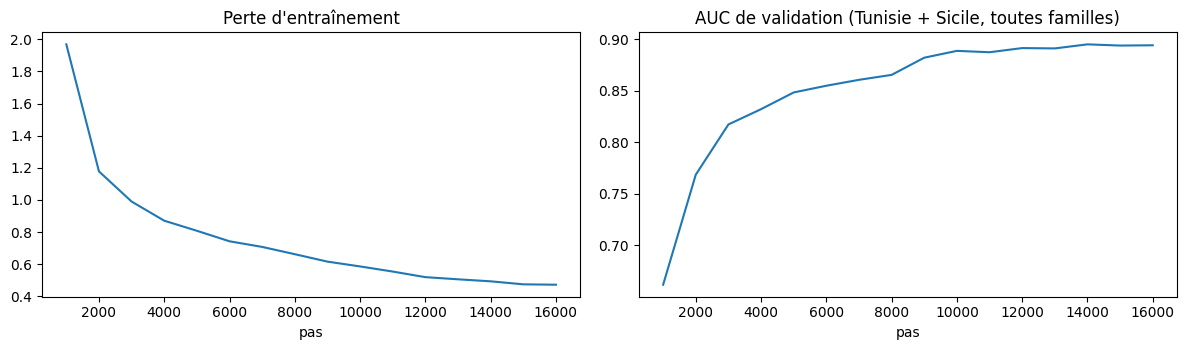

meilleur AUC de validation : 0.895 au pas 14000


In [5]:
cfg = default_cfg(steps=STEPS, bs=BS, eval_every=EVAL_EVERY, val_rep=VAL_REP, num_workers=NUM_WORKERS, seed=SEED, weights=WEIGHTS,
                  names=TRAIN_NAMES, min_detect=MIN_DETECT, p_hard=P_HARD, **BENIGN)
model, hist = train_variant(VARIANT, stats, {'train': data['train'], 'val': val_mix}, cfg, device)
hist.to_csv(OUTM / 'history_final.csv', index=False)
torch.save(model.state_dict(), OUTM / 'detector_best.pt')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(hist.step, hist.loss); ax[0].set_title('Perte d\'entraînement'); ax[0].set_xlabel('pas')
ax[1].plot(hist.step, hist.val_auc); ax[1].set_title('AUC de validation (Tunisie + Sicile, toutes familles)'); ax[1].set_xlabel('pas')
plt.tight_layout(); plt.show()
print('meilleur AUC de validation :', round(float(hist.val_auc.max()), 3), 'au pas', int(hist.step[hist.val_auc.idxmax()]))

## 3. Calibration robuste des seuils

Pour chaque groupe géographique (Tunisie, Sicile), on calcule les seuils qui laissent passer 5 % (`t_low`) et 0,5 % (`t_high`) des authentiques, **vrais nuages compris**. Le seuil final est le **plus exigeant des groupes** : aucune région ne dépasse la cible. Le coût est une détection un peu plus faible dans les régions « faciles » : le tableau ci-dessous le chiffre.

In [6]:
def calibrate_groups(model, groups, names, device, n_rep=4, min_detect=8.0, bs=32, nw=0, q_low=0.95, q_high=0.995):
    store = {}
    for g, split in groups.items():
        neg, hard = score_negatives(model, split, device, n_rep, seed=3000, bs=bs, nw=nw)
        ds = ChipDS(split['x'], split['off'], names, 1.0, train=False, seed=3500, repeat=n_rep, min_detect=min_detect)
        r = run_scores(model, ds, device, bs, nw)
        store[g] = dict(neg=neg, hard=hard, pos=r['scores'][r['labels'] > 0.5])
    t_low = max(float(np.quantile(v['neg'], q_low)) for v in store.values())
    t_high = max(float(np.quantile(v['neg'], q_high)) for v in store.values())
    neg = np.concatenate([v['neg'] for v in store.values()]); pos = np.concatenate([v['pos'] for v in store.values()])
    lr = LogisticRegression(C=1e4, class_weight='balanced', max_iter=1000).fit(np.r_[neg, pos].reshape(-1, 1), np.r_[np.zeros(len(neg)), np.ones(len(pos))])
    cal = {'t_low': t_low, 't_high': t_high, 'platt_a': float(lr.coef_[0, 0]), 'platt_b': float(lr.intercept_[0]),
           'n_neg': int(len(neg)), 'n_pos': int(len(pos)), 'politique': 'seuil le plus exigeant parmi les groupes géographiques'}
    rows = []
    for g, v in store.items():
        rows.append(dict(groupe=g, n_neg=len(v['neg']), fa_low=float((v['neg'] >= t_low).mean()), fa_high=float((v['neg'] >= t_high).mean()),
                         fa_nuages_low=float((v['neg'][v['hard']] >= t_low).mean()) if v['hard'].any() else np.nan,
                         n_pos=len(v['pos']), detection_low=float((v['pos'] >= t_low).mean()), detection_high=float((v['pos'] >= t_high).mean()),
                         seuil_propre_low=float(np.quantile(v['neg'], q_low)), seuil_propre_high=float(np.quantile(v['neg'], q_high))))
    return cal, pd.DataFrame(rows)

cal, cal_tab = calibrate_groups(model, groups, TRAIN_NAMES, device, n_rep=2 if not QUICK else 1, min_detect=MIN_DETECT, bs=BS, nw=NUM_WORKERS)
cal_tab.to_csv(OUTM / 'calibration_groupes.csv', index=False)
display(cal_tab.round(3))
print('seuils retenus :', {k: round(cal[k], 3) for k in ['t_low', 't_high']})

,groupe,n_neg,fa_low,fa_high,fa_nuages_low,n_pos,detection_low,detection_high,seuil_propre_low,seuil_propre_high
0,tunisie_val,664,0.029,0.000,0.132,664,0.758,0.664,1.306,3.975
1,sicile_externe,858,0.050,0.006,0.138,858,0.681,0.561,2.778,6.877


seuils retenus : {'t_low': 2.778, 't_high': 6.877}


## 4. Évaluation sur le jeu de test tunisien (jamais utilisé), avec incertitude

Les AUC sont accompagnées d'un **intervalle de confiance à 95 %** (bootstrap par chip : on retire des chips avec remise, car 86 chips de test ne suffisent pas à fixer un chiffre unique). Lisez surtout la **largeur** des intervalles.

,famille,role,n_req,n_pos,fp_low,fp_high,rejet,auc,ap,tpr_low,tpr_high,iou,dice,ic95_bas,ic95_haut
0,(authentiques),négatifs,172,0,0.093,0.012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,(authentiques nuageux),négatifs réels,30,0,0.233,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,copy_move,entraînement,172,172,NaN,NaN,0.0,0.730,0.761,0.360,0.244,0.241,0.281,0.682,0.773
3,splice,entraînement,172,172,NaN,NaN,0.0,0.889,0.906,0.651,0.523,0.516,0.572,0.851,0.925
4,class_swap,entraînement,172,172,NaN,NaN,0.0,0.913,0.931,0.750,0.616,0.616,0.684,0.874,0.945
5,rotate,entraînement,172,172,NaN,NaN,0.0,0.880,0.891,0.616,0.424,0.471,0.544,0.839,0.916
6,scale,entraînement,172,172,NaN,NaN,0.0,0.896,0.929,0.797,0.738,0.624,0.680,0.868,0.927
7,spectral,entraînement,172,172,NaN,NaN,0.0,0.833,0.867,0.593,0.483,0.455,0.510,0.785,0.878
8,photometric,entraînement,172,172,NaN,NaN,0.0,0.600,0.577,0.110,0.029,0.053,0.062,0.566,0.652
9,noise,entraînement,172,172,NaN,NaN,0.0,0.978,0.983,0.930,0.855,0.754,0.814,0.961,0.990


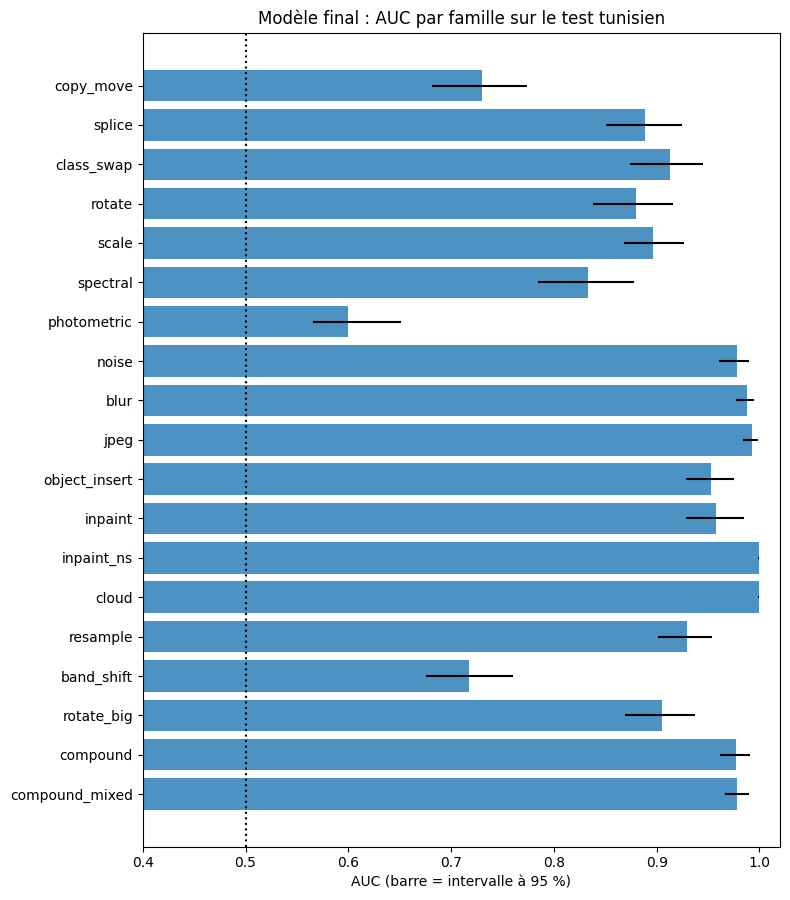

fausses alarmes sur le test : t_low 0.093  t_high 0.012 | vrais nuages (n=30) : t_low 0.233  t_high 0.000


In [7]:
full = family_table(model, data['test'], EVAL_FAMILIES, ROLES, cal, device, n_rep=N_REP, min_detect=MIN_DETECT, bs=BS, nw=NUM_WORKERS)

def chip_bootstrap(model, split, fam, n_boot=300, n_rep=2, seed=0):
    N = len(split['x'])
    neg, _ = score_negatives(model, split, device, n_rep=n_rep, seed=1000, bs=BS, nw=NUM_WORKERS)
    ds = ChipDS(split['x'], split['off'], [fam], 1.0, train=False, seed=2000, repeat=n_rep, min_detect=MIN_DETECT)
    r = run_scores(model, ds, device, BS, NUM_WORKERS)
    ok = r['labels'] > 0.5
    pos, chip_pos = r['scores'][ok], (np.arange(len(ds)) % N)[ok]
    chip_neg = np.arange(len(neg)) % N
    y = np.r_[np.zeros(len(neg)), np.ones(len(pos))]; s = np.r_[neg, pos]; c = np.r_[chip_neg, chip_pos]
    rng_b = np.random.default_rng(seed); aucs = []
    for _ in range(n_boot):
        w = np.bincount(rng_b.integers(0, N, N), minlength=N)[c]
        if w[y == 0].sum() > 0 and w[y == 1].sum() > 0:
            aucs.append(roc_auc_score(y, s, sample_weight=w))
    return float(roc_auc_score(y, s)), float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))

ic = pd.DataFrame([dict(famille=f, **dict(zip(['auc', 'ic95_bas', 'ic95_haut'], chip_bootstrap(model, data['test'], f, N_BOOT, N_REP)))) for f in EVAL_FAMILIES])
res = full.merge(ic[['famille', 'ic95_bas', 'ic95_haut']], on='famille', how='left')
res.to_csv(OUTM / 'evaluation_test_final.csv', index=False)
display(res.round(3))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(ic) + 1.5))
ax.barh(ic.famille[::-1], ic.auc[::-1], xerr=[(ic.auc - ic.ic95_bas)[::-1], (ic.ic95_haut - ic.auc)[::-1]], color='tab:blue', alpha=.8)
ax.axvline(0.5, color='k', ls=':'); ax.set_xlim(0.4, 1.02); ax.set_xlabel('AUC (barre = intervalle à 95 %)'); ax.set_title('Modèle final : AUC par famille sur le test tunisien')
plt.tight_layout(); plt.show()
neg_t, hard_t = score_negatives(model, data['test'], device, n_rep=N_REP, seed=1000, bs=BS, nw=NUM_WORKERS)
print(f'fausses alarmes sur le test : t_low {float((neg_t >= cal["t_low"]).mean()):.3f}  t_high {float((neg_t >= cal["t_high"]).mean()):.3f}', end='')
if hard_t.any(): print(f' | vrais nuages (n={int(hard_t.sum())}) : t_low {float((neg_t[hard_t] >= cal["t_low"]).mean()):.3f}  t_high {float((neg_t[hard_t] >= cal["t_high"]).mean()):.3f}')

## 5. Test de stress : des scènes **authentiques** légèrement retraitées doivent rester TRUSTED

Des chips authentiques du test subissent des variations **légitimes** (étalonnage radiométrique différent, bruit supplémentaire). Un modèle robuste ne doit pas déclencher d'alerte. Si les fausses alarmes montent nettement, élargissez `BENIGN` et réentraînez.

,traitement,n,fa_suspicious,fa_compromised,score_median
0,aucune,86,0.116,0.012,-1.534
1,"gain x0,90",86,0.105,0.012,-1.511
2,"gain x1,10",86,0.116,0.012,-1.533
3,bruit +20 DN,86,0.035,0.000,-1.784
4,bruit +40 DN,86,0.012,0.000,-1.714
5,"gain x1,05 + bruit 20",86,0.035,0.000,-1.779


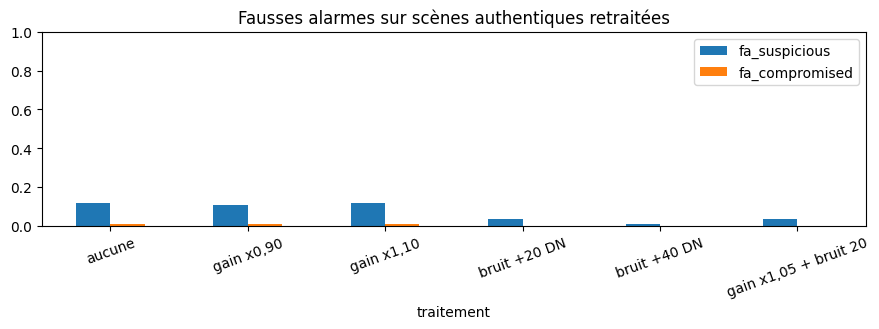

In [8]:
an = Analyzer(model, device, cal)
te = data['test']
stress = {
    'aucune': lambda x, o, r: x,
    'gain x0,90': lambda x, o, r: to_u16((x.astype(np.float32) - o) * 0.90 + o),
    'gain x1,10': lambda x, o, r: to_u16((x.astype(np.float32) - o) * 1.10 + o),
    'bruit +20 DN': lambda x, o, r: to_u16(x.astype(np.float32) + r.normal(0, 20, x.shape)),
    'bruit +40 DN': lambda x, o, r: to_u16(x.astype(np.float32) + r.normal(0, 40, x.shape)),
    'gain x1,05 + bruit 20': lambda x, o, r: to_u16((x.astype(np.float32) - o) * 1.05 + o + r.normal(0, 20, x.shape)),
}
rows = []
for name, fn in stress.items():
    r_ = np.random.default_rng(123)
    sc = np.array([an.analyze(fn(te['x'][i], float(te['off'][i]), r_), float(te['off'][i]))['score'] for i in range(len(te['x']))])
    rows.append(dict(traitement=name, n=len(sc), fa_suspicious=float((sc >= cal['t_low']).mean()), fa_compromised=float((sc >= cal['t_high']).mean()), score_median=float(np.median(sc))))
stress_tab = pd.DataFrame(rows); stress_tab.to_csv(OUTM / 'test_stress.csv', index=False)
display(stress_tab.round(3))
ax = stress_tab.set_index('traitement')[['fa_suspicious', 'fa_compromised']].plot.bar(figsize=(9, 3.4), rot=20)
ax.set_title('Fausses alarmes sur scènes authentiques retraitées'); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

## 6. Exemples tirés au hasard (le modèle ne sait pas ce qui est falsifié)

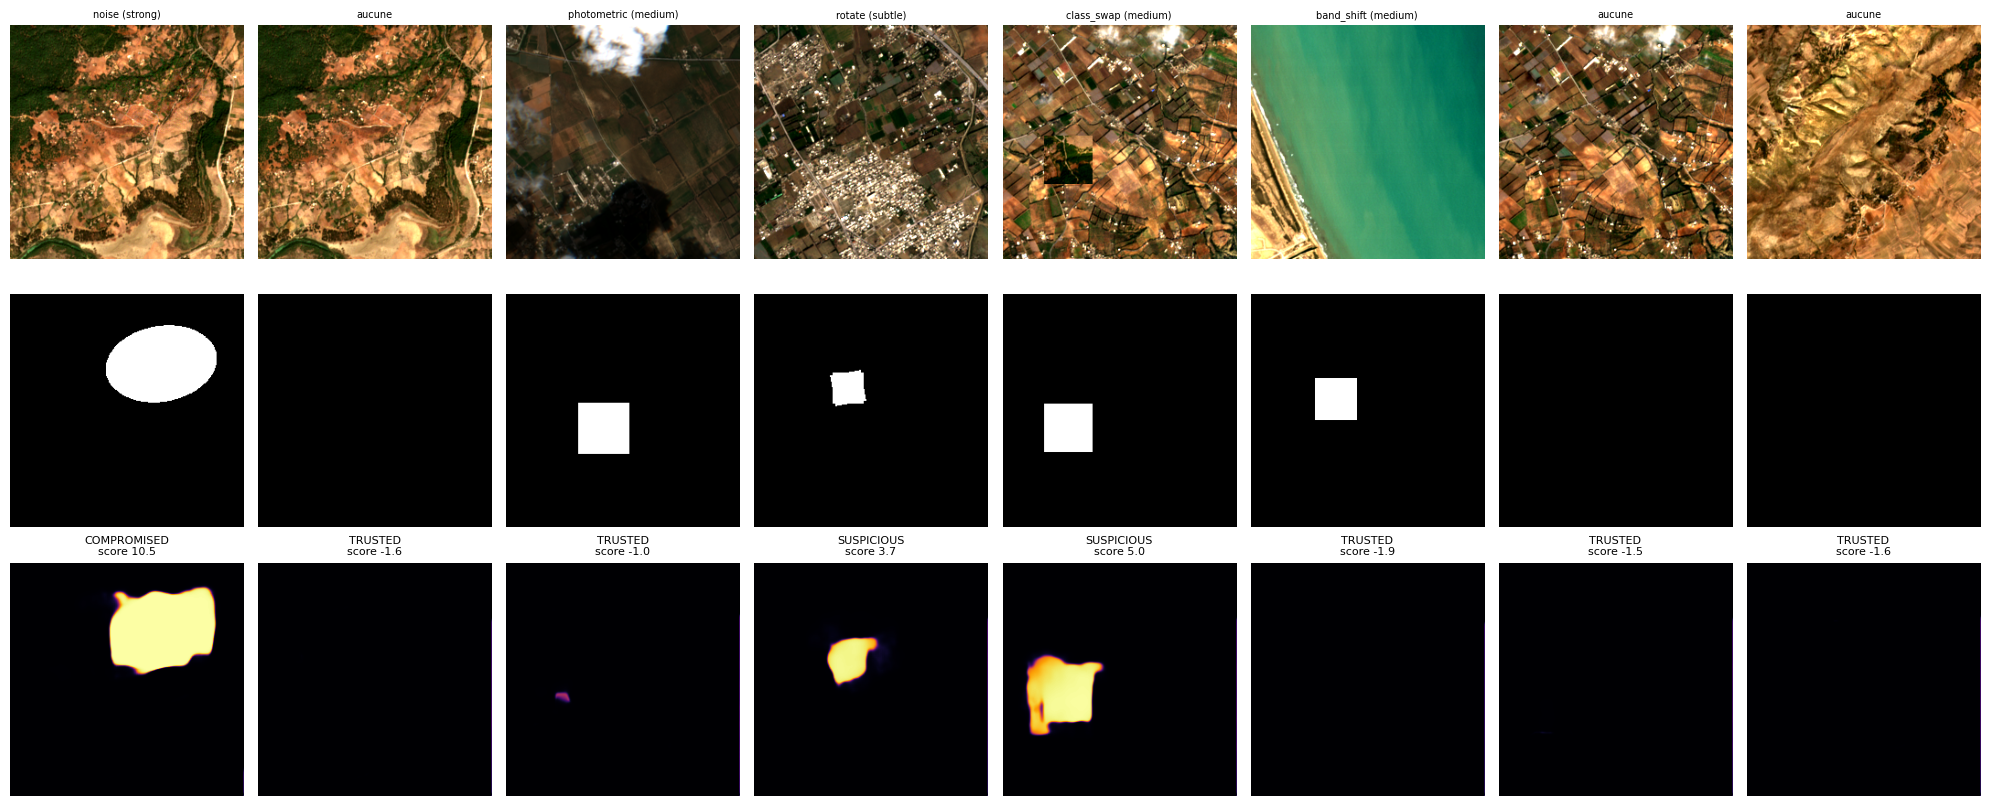

In [9]:
def show_rgb(x):
    rgb = x[[2, 1, 0]].astype(np.float32); lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1).transpose(1, 2, 0)

rng_q = np.random.default_rng()
fig, axs = plt.subplots(3, 8, figsize=(20, 8.2))
for c_ in range(8):
    i = int(rng_q.integers(len(te['x']))); off = float(te['off'][i]); base = te['x'][i]
    if rng_q.random() < 0.5:
        j = (i + int(rng_q.integers(1, len(te['x'])))) % len(te['x'])
        donor = to_u16(te['x'][j].astype(np.float32) - te['off'][j] + off)
        fam = str(rng_q.choice(EVAL_FAMILIES)); sev = str(rng_q.choice(SEV_ALL))
        img, m, rec = make_attack(base, donor, fam, sev, rng_q, off); truth = f'{fam} ({sev})'
        if m.sum() == 0: img, m, truth = base, np.zeros(base.shape[1:], np.uint8), 'aucune'
    else:
        img, m, truth = base, np.zeros(base.shape[1:], np.uint8), 'aucune' + (' (nuageuse réelle)' if te['hard'][i] else '')
    r = an.analyze(img, off)
    verdict = 'COMPROMISED' if r['score'] >= cal['t_high'] else 'SUSPICIOUS' if r['score'] >= cal['t_low'] else 'TRUSTED'
    axs[0, c_].imshow(show_rgb(img)); axs[0, c_].set_title(truth, fontsize=7)
    axs[1, c_].imshow(m, cmap='gray', vmin=0, vmax=1)
    axs[2, c_].imshow(r['prob'], cmap='inferno', vmin=0, vmax=1); axs[2, c_].set_title(f'{verdict}\nscore {r["score"]:.1f}', fontsize=8)
    for r_ in range(3): axs[r_, c_].axis('off')
plt.tight_layout(); plt.show()

## 7. Export du modèle final et emballage

Le dossier `model_final/` contient tout ce que le notebook 03 attend (`config.json`, `detector_best.pt`) et l'ONNX pour le tableau de bord. L'archive `tp_model_final.zip` regroupe l'essentiel : téléchargez-la depuis l'onglet *Output*.

In [10]:
onnx_path = export_onnx(model, str(OUTM / 'detector.onnx'))
chk = onnx_check(model, onnx_path)
print('ONNX :', {k: round(v, 5) for k, v in chk.items()})
assert chk['ecart_rel'] < 1e-3, 'écart PyTorch/ONNX trop grand'
config = {'variant': VARIANT, 'mode': 'production', 'role': 'modele_final', 'encoder': 'resnet18', 'mean': stats['mean'], 'std': stats['std'],
          'hp_std': stats['hp_std'], 'bands': BANDS, 'chip': CHIP, 'default_offset': DEFAULT_OFFSET, 'calibration': cal,
          'train_families': TRAIN_NAMES, 'all_families': EVAL_FAMILIES, 'min_detect': MIN_DETECT, 'steps': STEPS, 'p_hard': P_HARD, 'benign': BENIGN,
          'data_manifest_sha256': file_sha256(str(DATA_DIR / 'data_manifest.json')), 'val_auc': float(hist.val_auc.max()), 'onnx': chk}
json.dump(config, open(OUTM / 'config.json', 'w'), indent=1)
import shutil
pkg = ROOT / 'tp_model_final'; pkg.mkdir(exist_ok=True)
for f in ['detector_best.pt', 'config.json', 'detector.onnx', 'history_final.csv', 'calibration_groupes.csv', 'evaluation_test_final.csv', 'test_stress.csv']:
    shutil.copy(OUTM / f, pkg / f)
shutil.make_archive(str(ROOT / 'tp_model_final'), 'zip', pkg)
print(sorted(os.listdir(pkg)), '|', round(os.path.getsize(ROOT / 'tp_model_final.zip') / 1e6), 'Mo')
print('seuils :', {k: round(cal[k], 3) for k in ['t_low', 't_high']}, '| variante', VARIANT)

ONNX : {'ecart_max': 2e-05, 'ecart_rel': 0.0, 'ms_par_chip': 59.24363, 'taille_mo': 57.38377}
['calibration_groupes.csv', 'config.json', 'detector.onnx', 'detector_best.pt', 'evaluation_test_final.csv', 'history_final.csv', 'test_stress.csv'] | 107 Mo
seuils : {'t_low': 2.778, 't_high': 6.877} | variante M1


In [11]:
# Cellule à ajouter après l'export ONNX
te = data['test']
idx = list(range(0, len(te['x']), max(1, len(te['x']) // 12)))[:12]
an = Analyzer(model, device, cal)
gold_px = np.stack([te['x'][i] for i in idx])
gold_off = np.array([te['off'][i] for i in idx], dtype=np.float32)
res = [an.analyze(te['x'][i], float(te['off'][i])) for i in idx]
np.savez_compressed(OUTM / 'golden.npz', pixels=gold_px, offsets=gold_off,
                    scores=np.array([r['score'] for r in res], dtype=np.float32),
                    probs=np.stack([r['prob'] for r in res]).astype(np.float32))
shutil.copy(OUTM / 'golden.npz', pkg / 'golden.npz')
shutil.make_archive(str(ROOT / 'tp_model_final'), 'zip', pkg)

'/kaggle/working/tp_model_final.zip'

## Et ensuite

1. **Téléchargez** `tp_model_final.zip` (onglet *Output*). Décompressez-le sur votre PC.
2. **Kaggle → Create → New Dataset** : glissez `config.json` et `detector_best.pt` (et le reste si vous voulez), nom `tp-model-final`, *Create*.
3. **Notebook 03** : *Add Input* → **uniquement** `tp-model-final` (pas l'ancien `tp-model` : le notebook prend le premier `config.json` qu'il trouve) et votre dataset de données. Lancez-le : c'est le test réel du modèle final, avec signature et scénarios aléatoires.
4. **Rapport** : `evaluation_test_final.csv` (AUC avec intervalles), `calibration_groupes.csv`, `test_stress.csv`, `history_final.csv`.